# DX 704 Week 9 Project

This week's project will build an email spam classifier based on the Enron email data set.
You will perform your own feature extraction, and use naive Bayes to estimate the probability that a particular email is spam or not.
Finally, you will review the tradeoffs from different thresholds for automatically sending emails to the junk folder.

The full project description and a template notebook are available on GitHub: [Project 9 Materials](https://github.com/bu-cds-dx704/dx704-project-09).


## Example Code

You may find it helpful to refer to these GitHub repositories of Jupyter notebooks for example code.

* https://github.com/bu-cds-omds/dx601-examples
* https://github.com/bu-cds-omds/dx602-examples
* https://github.com/bu-cds-omds/dx603-examples
* https://github.com/bu-cds-omds/dx704-examples

Any calculations demonstrated in code examples or videos may be found in these notebooks, and you are allowed to copy this example code in your homework answers.

## Part 1: Download Data Set

We will be using the Enron spam data set as prepared in this GitHub repository.

https://github.com/MWiechmann/enron_spam_data

You may need to download this differently depending on your environment.

In [1]:
!wget https://github.com/MWiechmann/enron_spam_data/raw/refs/heads/master/enron_spam_data.zip

--2026-11-02 05:15:51--  https://github.com/MWiechmann/enron_spam_data/raw/refs/heads/master/enron_spam_data.zip
Resolving github.com (github.com)... 140.82.114.3
Connecting to github.com (github.com)|140.82.114.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/MWiechmann/enron_spam_data/refs/heads/master/enron_spam_data.zip [following]
--2026-11-02 05:15:51--  https://raw.githubusercontent.com/MWiechmann/enron_spam_data/refs/heads/master/enron_spam_data.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.109.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 15642124 (15M) [application/zip]
Saving to: ‘enron_spam_data.zip’

enron_spam_data.zip 100%[===================>]  14.92M  --.-KB/s    in 0.1s    

2026-11-02 05:15:51 (99.7 MB/s) - ‘enron_spa

In [2]:
%pip install pandas numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 19.5 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 27.8 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 26.1 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 21.3 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 24.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 29.9 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [matplotlib]9 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd

In [5]:
# pandas can read the zip file directly
enron_spam_data = pd.read_csv("enron_spam_data.zip")
enron_spam_data

,Message ID,Subject,Message,Spam/Ham,Date
0,0,christmas tree farm pictures,NaN,ham,1999-12-10
1,1,"vastar resources , inc .","gary , production from the high island larger ...",ham,1999-12-13
2,2,calpine daily gas nomination,- calpine daily gas nomination 1 . doc,ham,1999-12-14
3,3,re : issue,fyi - see note below - already done .\nstella\...,ham,1999-12-14
4,4,meter 7268 nov allocation,fyi .\n- - - - - - - - - - - - - - - - - - - -...,ham,1999-12-14
...,...,...,...,...,...
33711,33711,= ? iso - 8859 - 1 ? q ? good _ news _ c = eda...,"hello , welcome to gigapharm onlinne shop .\np...",spam,2005-07-29
33712,33712,all prescript medicines are on special . to be...,i got it earlier than expected and it was wrap...,spam,2005-07-29
33713,33713,the next generation online pharmacy .,are you ready to rock on ? let the man in you ...,spam,2005-07-30
33714,33714,bloow in 5 - 10 times the time,learn how to last 5 - 10 times longer in\nbed ...,spam,2005-07-30


In [6]:
(enron_spam_data["Spam/Ham"] == "spam").mean()

np.float64(0.5092834262664611)

## Part 2: Design a Feature Extractor

Design a feature extractor for this data set and write out two files of features based on the text.
Don't forget that both the Subject and Message columns are relevant sources of text data.
For each email, you should count the number of repetitions of each feature present.
The auto-grader will assume that you are using a multinomial distribution in the following problems.

In [7]:
# YOUR CHANGES HERE

import re
import json
from collections import Counter

def extract_features(subject, message):
    # Replace missing subjects or messages with empty strings
    subject = "" if pd.isna(subject) else str(subject)
    message = "" if pd.isna(message) else str(message)

    text = (subject + " " + message).lower()

    # Extract words with at least two letters
    words = re.findall(r"[a-z]{2,}", text)

    return dict(Counter(words))

enron_spam_data["features_json"] = enron_spam_data.apply(
    lambda row: json.dumps(
        extract_features(row["Subject"], row["Message"])
    ),
    axis=1
)

enron_spam_data[["Message ID", "features_json"]].head()

,Message ID,features_json
0,0,"{""christmas"": 1, ""tree"": 1, ""farm"": 1, ""pictur..."
1,1,"{""vastar"": 6, ""resources"": 4, ""inc"": 4, ""gary""..."
2,2,"{""calpine"": 2, ""daily"": 2, ""gas"": 2, ""nominati..."
3,3,"{""re"": 2, ""issue"": 4, ""fyi"": 1, ""see"": 1, ""not..."
4,4,"{""meter"": 3, ""nov"": 3, ""allocation"": 3, ""fyi"":..."


Assign a row to the test data set if `Message ID % 30 == 0` and assign it to the training data set otherwise.
Write two files, "train-features.tsv" and "test-features.tsv" with two columns, Message ID and features_json.
The features_json column should contain a JSON dictionary where the keys are your feature names and the values are integer feature values.
This will give us a sparse feature representation.


In [9]:
# YOUR CHANGES HERE

# Follow the assignment's required train/test split
test_mask = enron_spam_data["Message ID"] % 30 == 0

train_data = enron_spam_data.loc[~test_mask].copy()
test_data = enron_spam_data.loc[test_mask].copy()

columns = ["Message ID", "features_json"]

train_data[columns].to_csv(
    "train-features.tsv", sep="\t", index=False
)

test_data[columns].to_csv(
    "test-features.tsv", sep="\t", index=False
)

print("Training emails:", len(train_data))
print("Test emails:", len(test_data))

Training emails: 32592
Test emails: 1124


Submit "train-features.tsv" and "test-features.tsv" in Gradescope.

Hint: these features will be graded based on the test accuracy of a logistic regression based on the training features.
This is to make sure that your feature set is not degenerate; you do not need to compute this regression yourself.
You can separately assess your feature quality based on your results in part 6.

## Part 3: Compute Conditional Probabilities

Based on your training data, compute appropriate conditional probabilities for use with naïve Bayes.
Use of additive smoothing with $\alpha=1$ to avoid zeros.


In [10]:
# YOUR CHANGES HERE

ham_counts = Counter()
spam_counts = Counter()

for _, row in train_data.iterrows():
    features = json.loads(row["features_json"])

    if row["Spam/Ham"] == "ham":
        ham_counts.update(features)
    else:
        spam_counts.update(features)

# Vocabulary contains all words found in training
vocabulary = sorted(set(ham_counts) | set(spam_counts))
vocab_size = len(vocabulary)

total_ham_words = sum(ham_counts.values())
total_spam_words = sum(spam_counts.values())

# Additive smoothing with alpha = 1
feature_probabilities = pd.DataFrame({
    "feature": vocabulary,
    "ham_probability": [
        (ham_counts[word] + 1) / (total_ham_words + vocab_size)
        for word in vocabulary
    ],
    "spam_probability": [
        (spam_counts[word] + 1) / (total_spam_words + vocab_size)
        for word in vocabulary
    ]
})

print("Vocabulary size:", vocab_size)
feature_probabilities.head(10)

Vocabulary size: 141210


,feature,ham_probability,spam_probability
0,aa,5.394442e-05,5.654400e-05
1,aaa,4.187466e-06,5.838783e-06
2,aaaa,2.463216e-07,9.219130e-07
3,aaaacy,2.463216e-07,6.146087e-07
4,aaaahhhhhh,4.926431e-07,3.073043e-07
5,aaadrizzle,2.463216e-07,9.219130e-07
6,aaaenerfax,4.926431e-07,3.073043e-07
7,aaagrp,2.463216e-07,6.146087e-07
8,aaal,2.463216e-07,6.146087e-07
9,aaaplusdirect,2.463216e-07,6.146087e-07


Save the conditional probabilities in a file "feature-probabilities.tsv" with columns feature, ham_probability and spam_probability.

In [11]:
# YOUR CHANGES HERE

feature_probabilities.to_csv(
    "feature-probabilities.tsv",
    sep="\t",
    index=False
)

print("Ham probability sum:",
      feature_probabilities["ham_probability"].sum())
print("Spam probability sum:",
      feature_probabilities["spam_probability"].sum())

Ham probability sum: 1.0
Spam probability sum: 1.0


Submit "feature-probabilities.tsv" in Gradescope.

## Part 4: Implement a Naïve Bayes Classifier

Implement a naïve Bayes classifier based on your previous feature probabilities.

In [12]:
# YOUR CHANGES HERE

import numpy as np

# Prior probabilities from training emails
class_priors = (
    train_data["Spam/Ham"]
    .value_counts(normalize=True)
)

# Store log probabilities for quick lookup
log_ham_probs = dict(zip(
    feature_probabilities["feature"],
    np.log(feature_probabilities["ham_probability"])
))

log_spam_probs = dict(zip(
    feature_probabilities["feature"],
    np.log(feature_probabilities["spam_probability"])
))

def predict_probabilities(features_json):
    features = json.loads(features_json)

    ham_score = np.log(class_priors["ham"])
    spam_score = np.log(class_priors["spam"])

    for word, count in features.items():
        # Ignore words outside the training vocabulary
        if word in log_ham_probs:
            ham_score += count * log_ham_probs[word]
            spam_score += count * log_spam_probs[word]

    # Convert log scores to probabilities without underflow
    scores = np.array([ham_score, spam_score])
    probabilities = np.exp(scores - scores.max())
    probabilities /= probabilities.sum()

    return probabilities

Save your prediction probabilities to "train-predictions.tsv" with columns Message ID, ham and spam.

In [13]:
# YOUR CHANGES HERE

train_probs = np.array([
    predict_probabilities(features)
    for features in train_data["features_json"]
])

train_predictions = pd.DataFrame({
    "Message ID": train_data["Message ID"].to_numpy(),
    "ham": train_probs[:, 0],
    "spam": train_probs[:, 1]
})

train_predictions.to_csv(
    "train-predictions.tsv",
    sep="\t",
    index=False
)

print("Training predictions:", len(train_predictions))
train_predictions.head()

Training predictions: 32592


,Message ID,ham,spam
0,1,1.0,3.209370e-166
1,2,1.0,1.414829e-12
2,3,1.0,4.757984e-149
3,4,1.0,9.248879e-143
4,5,1.0,6.094001e-38


Submit "train-predictions.tsv" in Gradescope.

## Part 5: Predict Spam Probability for Test Data

Use your previous classifier to predict spam probability for the test data.
If the test data has tokens that you did not model, just ignore them.

In [14]:
# YOUR CHANGES HERE

test_probs = np.array([
    predict_probabilities(features)
    for features in test_data["features_json"]
])

test_predictions = pd.DataFrame({
    "Message ID": test_data["Message ID"].to_numpy(),
    "ham": test_probs[:, 0],
    "spam": test_probs[:, 1]
})

test_predictions.head()

,Message ID,ham,spam
0,0,0.058164,9.418357e-01
1,30,1.000000,2.105678e-79
2,60,1.000000,1.708586e-12
3,90,1.000000,7.263737e-33
4,120,1.000000,2.445817e-169


Save your prediction probabilities in "test-predictions.tsv" with the same columns as "train-predictions.tsv".

In [16]:
# YOUR CHANGES HERE

test_predictions.to_csv(
    "test-predictions.tsv",
    sep="\t",
    index=False
)

print("Test predictions:", len(test_predictions))
print(
    "Probabilities sum to 1:",
    np.allclose(
        test_predictions["ham"] + test_predictions["spam"],
        1
    )
)

Test predictions: 1124
Probabilities sum to 1: True


Submit "test-predictions.tsv" in Gradescope.

## Part 6: Construct ROC Curve

For every probability threshold from 0.01 to .99 in increments of 0.01, compute the false and true positive rates from the test data using the spam class for positives.
That is, if the predicted spam probability is greater than or equal to the threshold, predict spam.

In [17]:
# YOUR CHANGES HERE

# Match actual labels to the prediction rows by Message ID
actual_labels = test_predictions["Message ID"].map(
    test_data.set_index("Message ID")["Spam/Ham"]
)

actual_spam = actual_labels.eq("spam").to_numpy()
spam_probabilities = test_predictions["spam"].to_numpy()

roc_rows = []

for step in range(1, 100):
    threshold = step / 100
    predicted_spam = spam_probabilities >= threshold

    true_positives = np.sum(predicted_spam & actual_spam)
    false_positives = np.sum(predicted_spam & ~actual_spam)

    true_positive_rate = true_positives / np.sum(actual_spam)
    false_positive_rate = false_positives / np.sum(~actual_spam)

    roc_rows.append({
        "threshold": threshold,
        "false_positive_rate": false_positive_rate,
        "true_positive rate": true_positive_rate
    })

roc_data = pd.DataFrame(roc_rows)
roc_data.head()

,threshold,false_positive_rate,true_positive rate
0,0.01,0.032609,0.996503
1,0.02,0.032609,0.996503
2,0.03,0.030797,0.996503
3,0.04,0.028986,0.996503
4,0.05,0.028986,0.994755


Save this data in a file "roc.tsv" with columns threshold, false_positive_rate and true_positive rate.

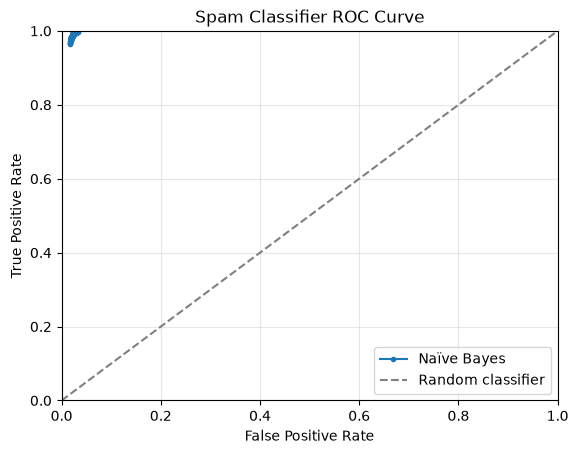

Thresholds saved: 99


In [18]:
# YOUR CHANGES HERE

roc_data.to_csv("roc.tsv", sep="\t", index=False)

import matplotlib.pyplot as plt

# Reverse threshold order so the curve runs from left to right
plt.plot(
    roc_data["false_positive_rate"].iloc[::-1],
    roc_data["true_positive rate"].iloc[::-1],
    marker=".",
    label="Naïve Bayes"
)

plt.plot([0, 1], [0, 1], "--", color="gray",
         label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Spam Classifier ROC Curve")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Thresholds saved:", len(roc_data))

In [19]:
roc_data = roc_data.rename(
    columns={"true_positive rate": "true_positive_rate"}
)

roc_data.to_csv("roc.tsv", sep="\t", index=False)

print(roc_data.columns.tolist())

['threshold', 'false_positive_rate', 'true_positive_rate']


Submit "roc.tsv" in Gradescope.

## Part 7: OpenAI API Key

Sign up for an OpenAI API acount at https://platform.openai.com/.
If you already have an OpenAI account (e.g. for ChatGPT), you may reuse that account.

Create a "dx704" project at https://platform.openai.com/settings/organization/projects, setup a $10/month spend limit, and create an API key for the project at https://platform.openai.com/api-keys.
You will use this API key for projects in later weeks.


No submission needed.

## Part 8: Code

Please submit a Jupyter notebook that can reproduce all your calculations and recreate the previously submitted files.
You do not need to provide code for data collection if you did that by manually.

## Part 9: Acknowledgements

If you discussed this assignment with anyone, please acknowledge them here.
If you did this assignment completely on your own, simply write none below.

If you used any libraries not mentioned in this module's content, please list them with a brief explanation what you used them for. If you did not use any other libraries, simply write none below.

If you used any generative AI tools, please add links to your transcripts below, and any other information that you feel is necessary to comply with the generative AI policy. If you did not use any generative AI tools, simply write none below.